# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "data/raw/hotel_bookings.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("../data/raw/hotel_bookings.csv"):
    CSV_PATH = "../data/raw/hotel_bookings.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Dataset Shape: 119,390 rows, 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# EDA 1: Schema, Missing Values, Duplicates & Target Leakage Audit

In [2]:
dup_count = df_raw.duplicated().sum()
print(f"Exact Duplicate Rows: {dup_count:,} ({dup_count / len(df_raw):.2%}) -> Leaves {len(df_raw) - dup_count:,} unique rows")

# Verify 100% Target Leakage in 'reservation_status'
print("\nCross-Tabulation proving 100% Target Leakage in 'reservation_status':")
display(pd.crosstab(df_raw["reservation_status"], df_raw["is_canceled"], margins=True))

audit_records = []
for col in df_raw.columns:
    null_count = df_raw[col].isnull().sum()
    if null_count > 0 or col in ["is_canceled", "lead_time", "adr", "adults", "children", "babies", "country", "deposit_type"]:
        audit_records.append({
            "Column": col,
            "Dtype": str(df_raw[col].dtype),
            "Null_Count": null_count,
            "Null_Pct (%)": round((null_count / len(df_raw)) * 100, 2),
            "Unique_Values": df_raw[col].nunique(),
            "Sample_Values": str(df_raw[col].dropna().unique()[:4]),
        })
display(pd.DataFrame(audit_records))

Exact Duplicate Rows: 31,994 (26.80%) -> Leaves 87,396 unique rows

Cross-Tabulation proving 100% Target Leakage in 'reservation_status':


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


,Column,Dtype,Null_Count,Null_Pct (%),Unique_Values,Sample_Values
0,is_canceled,int64,0,0.00,2,[0 1]
1,lead_time,int64,0,0.00,479,[342 737 7 13]
2,adults,int64,0,0.00,14,[2 1 3 4]
3,children,float64,4,0.00,5,[ 0. 1. 2. 10.]
4,babies,int64,0,0.00,5,[ 0 1 2 10]
5,country,str,488,0.41,177,"<StringArray>\n['PRT', 'GBR', 'USA', 'ESP']\nL..."
6,deposit_type,str,0,0.00,3,"<StringArray>\n['No Deposit', 'Refundable', 'N..."
7,agent,float64,16340,13.69,333,[304. 240. 303. 15.]
8,company,float64,112593,94.31,352,[110. 113. 270. 178.]
9,adr,float64,0,0.00,8879,[ 0. 75. 98. 107.]


# EDA 2: Ghost Bookings (0 Guests), ADR Outliers & Cancellation Drivers

1. Ghost Bookings (0 total guests: adults + children + babies == 0) : 180 rows
2. Negative Average Daily Rate (adr < 0)                            : 1 row (Min ADR: $-6.38)
3. Extreme ADR Outlier (adr > $1,000)                               : 1 row (Max ADR: $5400.00)

Raw Cancellation Rate          : 37.04%
Deduplicated Cancellation Rate : 27.49%


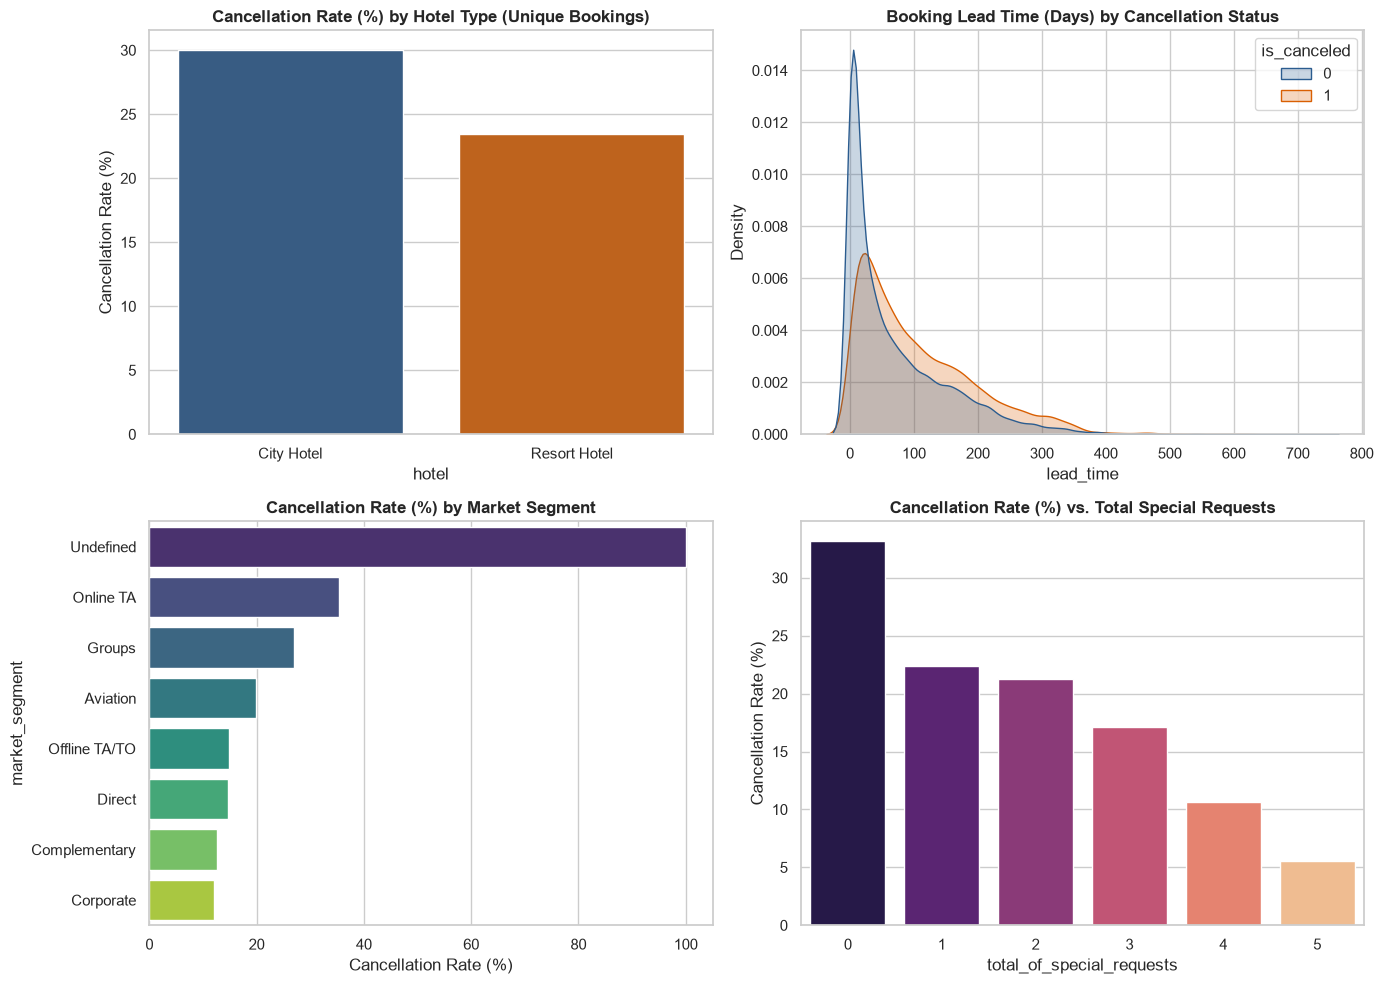

In [3]:
# 1. Check zero-guest bookings and ADR anomalies
total_guests = df_raw["adults"] + df_raw["children"].fillna(0) + df_raw["babies"]
zero_guest_rows = (total_guests == 0).sum()
neg_adr_rows = (df_raw["adr"] < 0).sum()
extreme_adr_rows = (df_raw["adr"] > 1000).sum()

print(f"1. Ghost Bookings (0 total guests: adults + children + babies == 0) : {zero_guest_rows} rows")
print(f"2. Negative Average Daily Rate (adr < 0)                            : {neg_adr_rows} row (Min ADR: ${df_raw['adr'].min():.2f})")
print(f"3. Extreme ADR Outlier (adr > $1,000)                               : {extreme_adr_rows} row (Max ADR: ${df_raw['adr'].max():.2f})")

# Compare cancellation rate before vs after deduplication
print(f"\nRaw Cancellation Rate          : {df_raw['is_canceled'].mean():.2%}")
df_dedup_preview = df_raw.drop_duplicates()
print(f"Deduplicated Cancellation Rate : {df_dedup_preview['is_canceled'].mean():.2%}")

# Visual EDA Dashboard (using deduplicated view for realistic behavioral patterns)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Cancellation Rate by Hotel Type
hotel_cancel = df_dedup_preview.groupby("hotel")["is_canceled"].mean() * 100
sns.barplot(x=hotel_cancel.index, y=hotel_cancel.values, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].set_title("Cancellation Rate (%) by Hotel Type (Unique Bookings)", fontweight="bold")
axes[0, 0].set_ylabel("Cancellation Rate (%)")

# Plot 2: Lead Time Distribution by Cancellation Status
sns.kdeplot(
    data=df_dedup_preview, x="lead_time", hue="is_canceled",
    fill=True, common_norm=False, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 1]
)
axes[0, 1].set_title("Booking Lead Time (Days) by Cancellation Status", fontweight="bold")

# Plot 3: Cancellation Rate by Market Segment
seg_cancel = df_dedup_preview.groupby("market_segment")["is_canceled"].mean().sort_values(ascending=False) * 100
sns.barplot(x=seg_cancel.values, y=seg_cancel.index, palette="viridis", ax=axes[1, 0])
axes[1, 0].set_title("Cancellation Rate (%) by Market Segment", fontweight="bold")
axes[1, 0].set_xlabel("Cancellation Rate (%)")

# Plot 4: Cancellation Rate by Number of Special Requests
req_cancel = df_dedup_preview.groupby("total_of_special_requests")["is_canceled"].mean() * 100
sns.barplot(x=req_cancel.index, y=req_cancel.values, palette="magma", ax=axes[1, 1])
axes[1, 1].set_title("Cancellation Rate (%) vs. Total Special Requests", fontweight="bold")
axes[1, 1].set_ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.savefig("outputs/eda_hotel_cancellation.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 31,994 exact duplicate rows so identical group/OTA batch records do not leak across train and test sets.
2. Drop post-event target leakage columns ('reservation_status', 'reservation_status_date') and post-check-in
   operational column ('assigned_room_type').
3. Drop 'company' (94.3% missing), 'agent' (high-cardinality ID replaced by binary has_agent flag), and 'arrival_date_year'.
4. Remove 180 ghost bookings where total guests (adults + children + babies) == 0, and remove corrupted ADR rows
   (adr < 0 or the single $5,400 data-entry outlier).
"""
df_clean = df_raw.drop_duplicates().copy()

# Create binary indicator before dropping high-missingness 'agent' and 'company' IDs
df_clean["has_booking_agent"] = df_clean["agent"].notnull().astype(int)
df_clean["has_corporate_account"] = df_clean["company"].notnull().astype(int)

# Fill the 4 missing values in 'children' with 0 and filter out 0-guest ghost bookings
df_clean["children"] = df_clean["children"].fillna(0)
total_guests = df_clean["adults"] + df_clean["children"] + df_clean["babies"]
df_clean = df_clean[total_guests > 0]

# Filter out negative ADR and the single $5,400 outlier
df_clean = df_clean[(df_clean["adr"] >= 0) & (df_clean["adr"] < 1000)].reset_index(drop=True)

# Consolidate 'Undefined' meal plan into 'SC' (Self Catering) per original dataset documentation
df_clean["meal"] = df_clean["meal"].replace({"Undefined": "SC"})

# Drop leakage and redundant columns
leakage_and_id_cols = [
    "reservation_status", "reservation_status_date", "assigned_room_type",
    "agent", "company", "arrival_date_year"
]
df_clean.drop(columns=leakage_and_id_cols, inplace=True)

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns | Cancellation Rate: {df_clean['is_canceled'].mean():.2%}")

Cleaned Dataset Shape: 87,228 rows, 28 columns | Cancellation Rate: 27.52%


# Domain Feature Engineering & Leak-Free Preprocessing

In [6]:
df_feat = df_clean.copy()

# 1. Total stay duration, total guests & estimated total booking revenue
df_feat["total_stay_nights"] = df_feat["stays_in_weekend_nights"] + df_feat["stays_in_week_nights"]
df_feat["total_guests"] = df_feat["adults"] + df_feat["children"] + df_feat["babies"]
df_feat["is_family_trip"] = ((df_feat["children"] + df_feat["babies"]) > 0).astype(int)
df_feat["total_booking_revenue"] = df_feat["adr"] * df_feat["total_stay_nights"]

# 2. Historical guest cancellation ratio & special request engagement
total_prior_bookings = df_feat["previous_cancellations"] + df_feat["previous_bookings_not_canceled"]
df_feat["historical_cancel_ratio"] = np.where(
    total_prior_bookings > 0, df_feat["previous_cancellations"] / total_prior_bookings, 0.0
)
df_feat["engagement_score"] = (
    df_feat["total_of_special_requests"] + df_feat["booking_changes"] + df_feat["required_car_parking_spaces"]
)

X = df_feat.drop(columns=["is_canceled"])
y = df_feat["is_canceled"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Cap high-cardinality 'country' using ONLY top 10 countries from X_train (strictly leak-free)
top_10_countries = X_train["country"].value_counts().nlargest(10).index.tolist()
X_train["country_grouped"] = X_train["country"].where(X_train["country"].isin(top_10_countries), "Other").fillna("Other")
X_test["country_grouped"] = X_test["country"].where(X_test["country"].isin(top_10_countries), "Other").fillna("Other")
X_train.drop(columns=["country"], inplace=True)
X_test.drop(columns=["country"], inplace=True)

cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (69782, 33) | Test Set: (17446, 33)


# Model Benchmarking (Logistic Regression vs. LightGBM Cancellation Engine)

In [7]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression (Balanced Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, n_jobs=-1, random_state=42)),
    ]),
    "LightGBM (Cancellation Risk Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LGBMClassifier(
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=63,
            max_depth=8,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_pr_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)

    print(f"\n---> {name}")
    print(f"ROC-AUC : {roc_auc:.4f} | PR-AUC : {pr_auc:.4f} | Optimal F1 Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Check-In (0)", "Canceled (1)"]))

    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_hotel_cancellation_model.joblib")


---> Logistic Regression (Balanced Baseline)
ROC-AUC : 0.8382 | PR-AUC : 0.6719 | Optimal F1 Threshold : 0.5392
              precision    recall  f1-score   support

Check-In (0)       0.89      0.77      0.83     12644
Canceled (1)       0.55      0.74      0.63      4802

    accuracy                           0.76     17446
   macro avg       0.72      0.76      0.73     17446
weighted avg       0.80      0.76      0.77     17446


---> LightGBM (Cancellation Risk Engine)
ROC-AUC : 0.8994 | PR-AUC : 0.7777 | Optimal F1 Threshold : 0.5495
              precision    recall  f1-score   support

Check-In (0)       0.91      0.84      0.87     12644
Canceled (1)       0.65      0.79      0.71      4802

    accuracy                           0.82     17446
   macro avg       0.78      0.81      0.79     17446
weighted avg       0.84      0.82      0.83     17446



['outputs/best_hotel_cancellation_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

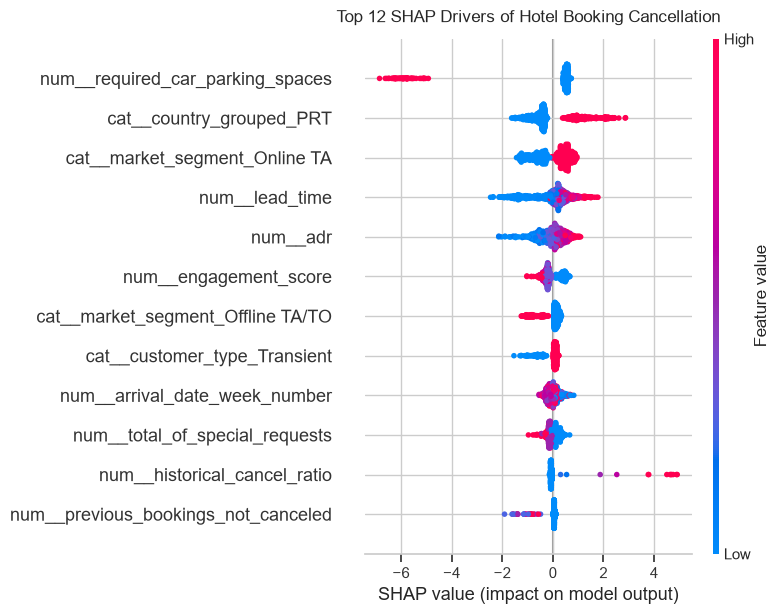

In [8]:
lgbm_pipe = models["LightGBM (Cancellation Risk Engine)"]

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)
shap_vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Hotel Booking Cancellation", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_hotel_cancellation.png", dpi=150)
plt.show()